# Atividade 3: Computação Quântica

Alunos:
- Lucas Maciel Ferreira
- Vinicius Ferreira Matias

Imports:

In [112]:
from numpy import sqrt
import numpy as np
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler as Sampler, BitArray
from qiskit.visualization import plot_histogram
from qiskit.circuit import *
from qiskit import QuantumCircuit
import math
import cmath

Criação dos registradores e inicialização do circuito:

In [113]:
qreg1 = QuantumRegister(1, 'qreg1')
qreg2 = QuantumRegister(1, 'qreg2')
creg1 = ClassicalRegister(2, 'creg1')

circuit = QuantumCircuit(qreg1, qreg2, creg1)

print("Quantum register 1 index: " + str(circuit.find_bit(qreg1[0]).index))
print("Quantum register 2 index: " + str(circuit.find_bit(qreg2[0]).index))
print("Classical register 1 index: " + str(circuit.find_bit(creg1[0]).index))

Quantum register 1 index: 0
Quantum register 2 index: 1
Classical register 1 index: 0


Aplicação da porta $H$ sobre o Qubit 0

In [114]:
circuit.h(0)
circuit.draw()

┌───┐
  qreg1: ┤ H ├
         └───┘
  qreg2: ─────
              
creg1: 2/═════

Aplicação da porta $T$ sobre o Qubit 0

In [115]:
circuit.t(0)
circuit.draw()

┌───┐┌───┐
  qreg1: ┤ H ├┤ T ├
         └───┘└───┘
  qreg2: ──────────
                   
creg1: 2/══════════

Aplicação da porta $CNOT$ sobre os Quibits 0 e 1

In [116]:
circuit.cx(0, 1)
circuit.draw()

┌───┐┌───┐     
  qreg1: ┤ H ├┤ T ├──■──
         └───┘└───┘┌─┴─┐
  qreg2: ──────────┤ X ├
                   └───┘
creg1: 2/═══════════════

Adicionando pontos de medição

In [117]:
circuit.measure([0,1],[0,1])
circuit.draw()

┌───┐┌───┐     ┌─┐   
  qreg1: ┤ H ├┤ T ├──■──┤M├───
         └───┘└───┘┌─┴─┐└╥┘┌─┐
  qreg2: ──────────┤ X ├─╫─┤M├
                   └───┘ ║ └╥┘
creg1: 2/════════════════╩══╩═
                         0  1

### Análise

Façamos uma análise do circuito, com os qubits sendo inicializados em $\ket{0}$. Ainda, dividimos o circuito em etapas, de forma a analisar cada parte. Definimos as etapas, conforme os estados abaixo:
- $\ket{\psi_1} = H\ket{0}\ket{0}$
- $\ket{\psi_2} = TH\ket{00}$
- $\ket{\psi_3} = CNOT(TH\ket{0}\ket{0})$

##### Análise de $\ket{\psi_1}$
Ao aplicar a porta Hadamard ao primeiro qubit, tem-se o seguinte:

$H\ket{0} = \frac{1}{\sqrt{2}}\times (\ket{0}\bra{0} + \ket{0}\bra{1} + \ket{1}\bra{0} - \ket{1}\bra{1})\ket{0} = \frac{1}{\sqrt{2}}\times (\ket{0}\bra{0}\ket{0} + \ket{0}\bra{1}\ket{0} + \ket{1}\bra{0}\ket{0} - \ket{1}\bra{1}\ket{0}) = $

$\frac{1}{\sqrt{2}}\times (\ket{0}\bra{0}\ket{0} + \ket{1}\bra{0}\ket{0}) = \frac{1}{\sqrt{2}}\times (\ket{0} + \ket{1}) = \ket{+}$

E, portanto:

$\ket{\psi_1}= H\ket{0}\ket{0}=\ket{+}\ket{0}$

##### Análise de $\ket{\psi_2}$
Ao aplicar a porta T ao estado $\ket{+}$, tem-se:

$T\ket{+} = (\ket{0}\bra{0} + e^{i\frac{\pi}{4}}\ket{1}\bra{1})\ket{+} = (\ket{0}\bra{0} + e^{i\frac{\pi}{4}}\ket{1}\bra{1})(\frac{1}{\sqrt{2}}\times (\ket{0} + \ket{1})) = $

$\frac{1}{\sqrt{2}}\times (\ket{0}\bra{0}\ket{0} + \ket{0}\bra{0}\ket{1} + e^{i\frac{\pi}{4}}\ket{1}\bra{1}\ket{0} + e^{i\frac{\pi}{4}}\ket{1}\bra{1}\ket{1}) = $

$\frac{1}{\sqrt{2}}\times (\ket{0}\bra{0}\ket{0} + e^{i\frac{\pi}{4}}\ket{1}\bra{1}\ket{1}) = \frac{1}{\sqrt{2}}\times(\ket{0} + e^{i\frac{\pi}{4}}\ket{1})$

E, portanto:

$\ket{\psi_2}= T\ket{+}\ket{0}=\frac{1}{\sqrt{2}}\times(\ket{0} + e^{i\frac{\pi}{4}}\ket{1})\ket{0}$

##### Análise de $\ket{\psi_3}$
Ao aplicar CNOT sobre $\ket{\psi_2}$, chega-se a:

$\ket{\psi_3} = CNOT(\ket{\psi_2}) = (\ket{00}\bra{00} + \ket{01}\bra{01} + \ket{11}\bra{10} + \ket{10}\bra{11})(\frac{1}{\sqrt{2}}\times(\ket{0} + e^{i\frac{\pi}{4}}\ket{1})\ket{0}) = $

$(\ket{00}\bra{00} + \ket{01}\bra{01} + \ket{11}\bra{10} + \ket{10}\bra{11})(\frac{1}{\sqrt{2}}\times(\ket{00} + e^{i\frac{\pi}{4}}\ket{10})) = $

$\frac{1}{\sqrt{2}}\times(\ket{00}\bra{00}\ket{00} + \ket{01}\bra{01}\ket{00} + \ket{11}\bra{10}\ket{00} + \ket{10}\bra{11}\ket{00} + e^{i\frac{\pi}{4}}(\ket{00}\bra{00}\ket{10} + \ket{01}\bra{01}\ket{10} + \ket{11}\bra{10}\ket{10} + \ket{10}\bra{11}\ket{10})) = $

$\frac{1}{\sqrt{2}}\times(\ket{00}\bra{00}\ket{00}  + e^{i\frac{\pi}{4}}\ket{11}\bra{10}\ket{10}) = \frac{1}{\sqrt{2}}\times(\ket{00}  + e^{i\frac{\pi}{4}}\ket{11})$

##### Análise Final: Significado e Probabilidades

Ao analisar o estado $\ket{\psi_3}$, percebe-se o emaranhamento dos bits quântico, já que o resultado da medição de um deles resulta em resultado conhecido para o outro. O mesmo ainda possui uma fase local em $\ket{11}$, evidenciado pelo termo $e^{i\frac{\pi}{4}}$. Conforme mostra o estado, os únicos resultados de medição possíveis são $00$ e $11$, com probabilidade de meio para cada, calculadas abaixo:

$p(00) = |\frac{1}{\sqrt{2}}|^{2} = \frac{1}{2}$

$p(11) = (|\frac{1}{\sqrt{2}}|\times|e^{i\frac{\pi}{4}}|)^{2} = |\frac{1}{\sqrt{2}}|^{2} = \frac{1}{2}$

PrimitiveResult([SamplerPubResult(data=DataBin(creg1=BitArray(<shape=(), num_shots=1024, num_bits=2>)), metadata={'shots': 1024, 'circuit_metadata': {}})], metadata={'version': 2})
{'00': 494, '11': 530}


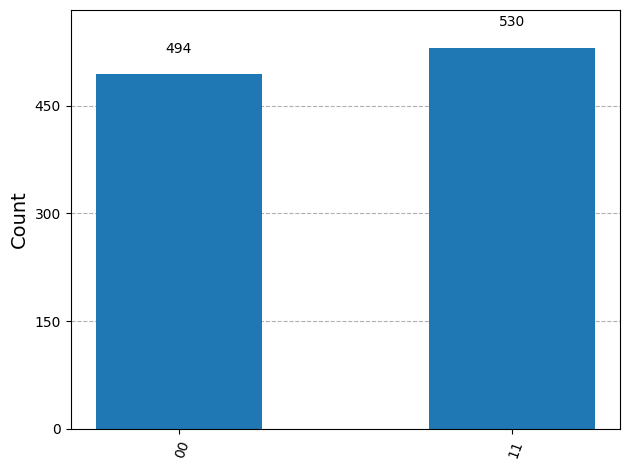

In [118]:
sampler = Sampler()
job = sampler.run([circuit])
result = job.result()

print(result)

data = result[0].data.creg1.get_counts()
print(data)

plot_histogram(data)